<a href="https://colab.research.google.com/github/OJB-Quantum/MuMax3-How-To/blob/main/MuMax%20Notebooks/ST_FMR_Ni4W_MuMaxPlus.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Authored by Onri Jay Benally (2026)

Open Access (CC-BY-4.0)

In [ ]:
!uv pip install mumaxplus matplotlib numpy

Completed 10/100: B = 75.0 mT, V_mix = 0.015 uV
Completed 20/100: B = 86.1 mT, V_mix = 0.020 uV
Completed 30/100: B = 97.2 mT, V_mix = 0.027 uV
Completed 40/100: B = 108.3 mT, V_mix = 0.031 uV
Completed 50/100: B = 119.4 mT, V_mix = -0.083 uV
Completed 60/100: B = 130.6 mT, V_mix = -0.050 uV
Completed 70/100: B = 141.7 mT, V_mix = -0.029 uV
Completed 80/100: B = 152.8 mT, V_mix = -0.021 uV
Completed 90/100: B = 163.9 mT, V_mix = -0.016 uV
Completed 100/100: B = 175.0 mT, V_mix = -0.013 uV
Resonance field B_res: 116.18 mT
Linewidth delta_B: 6.47 mT
Symmetric V_S: -0.053 uV, Antisymmetric V_A: -0.107 uV
Lorentzian ratio V_S / V_A: 0.499


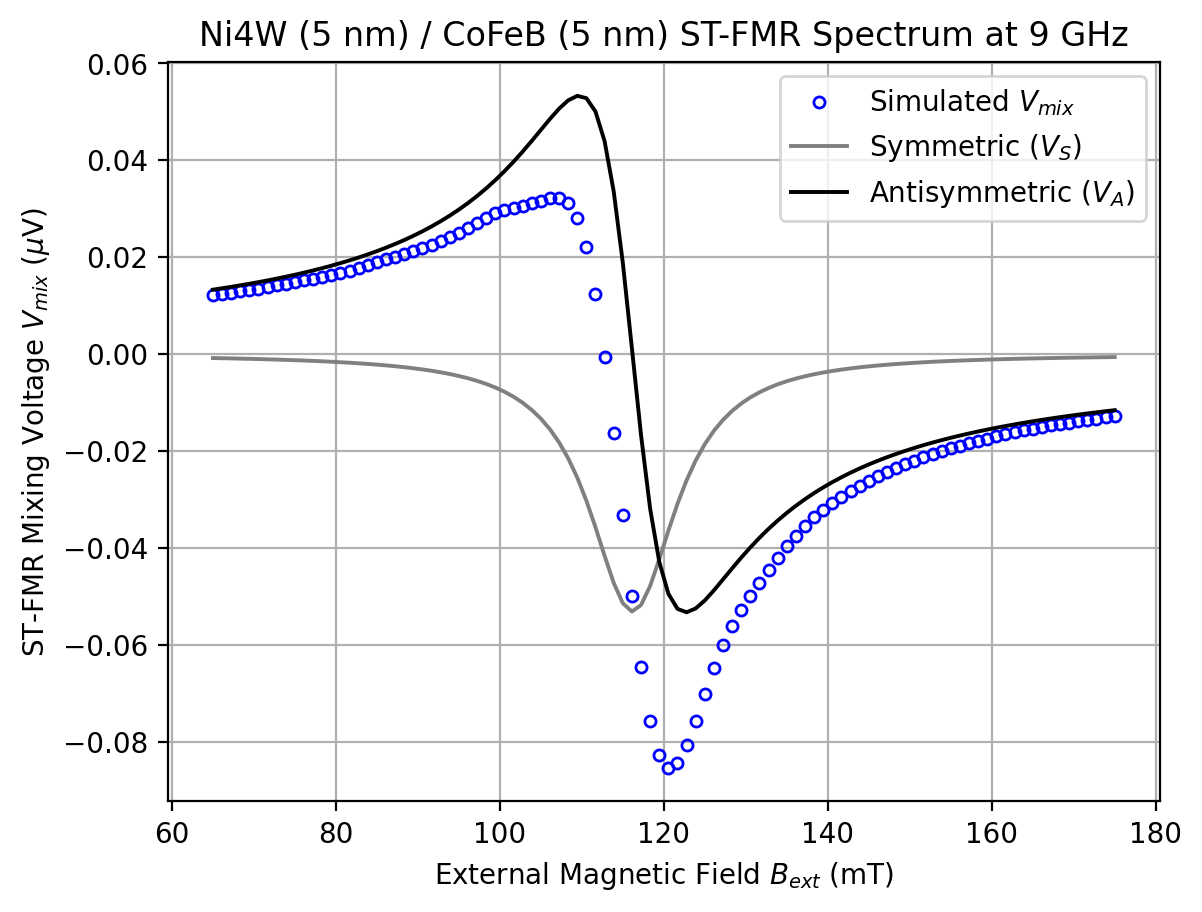

In [2]:
"""This script simulates ST-FMR in a Ni4W(5 nm)/CoFeB(5 nm) heterostructure.

The simulation drives a single-layer CoFeB thin film with multi-directional
spin-orbit torque and Oersted effective fields from Ni4W(211) on a GPU,
then extracts the DC mixing voltage and Lorentzian components.
"""

import math
import matplotlib.pyplot as plt
from mumaxplus import Ferromagnet
from mumaxplus import Grid
from mumaxplus import World
import numpy as np

plt.rcParams['figure.dpi'] = 200

mu0 = 4.0 * np.pi * 1e-7
hbar = 1.054571817e-34
q_e = 1.602176634e-19

msat = 1.0e6
aex = 15.0e-12
ku1 = 1.28e5
alpha = 0.02
t_fm = 5.0e-9
t_hm = 5.0e-9
rho_hm = 1.50e-6
rho_fm = 2.27e-6
width_strip = 10.0e-6
delta_r = 0.2

theta_dl_x = 0.091
theta_dl_y = 0.727
theta_dl_z = -0.022
theta_fl_y = 0.577
theta_fl_z = 0.025

j_rf = 2.0e9
f_rf = 9.0e9
omega = 2.0 * np.pi * f_rf
phi = np.deg2rad(45.0)

b_sot_unit = (hbar * j_rf) / (2.0 * q_e * msat * t_fm)
b_dl_x = theta_dl_x * b_sot_unit
b_dl_y = theta_dl_y * b_sot_unit
b_dl_z = theta_dl_z * b_sot_unit
b_fl_y = theta_fl_y * b_sot_unit
b_fl_z = theta_fl_z * b_sot_unit
b_oe = -0.5 * mu0 * j_rf * t_hm

b_rf_x = b_dl_z * np.sin(phi)
b_rf_y = b_fl_y + b_oe - b_dl_z * np.cos(phi)
b_rf_z = b_dl_y * np.cos(phi) - b_dl_x * np.sin(phi) + b_fl_z

i_hm = j_rf * width_strip * t_hm
i_rf = i_hm * (1.0 + (rho_hm * t_fm) / (rho_fm * t_hm))

world = World(cellsize=(4.0e-9, 4.0e-9, 5.0e-9))
magnet = Ferromagnet(world, Grid((16, 16, 1)))

magnet.msat = msat
magnet.aex = aex
magnet.ku1 = ku1
magnet.anisU = (0.0, 0.0, 1.0)
magnet.alpha = alpha

mask = np.ones((1, 16, 16))
magnet.bias_magnetic_field.add_time_term(
    lambda t: (
        b_rf_x * math.cos(omega * t),
        b_rf_y * math.cos(omega * t),
        b_rf_z * math.cos(omega * t),
    ),
    mask,
)

b_sweep = np.linspace(0.065, 0.175, 100)
t_ringup = 2.0e-9
t_measure = 1.0e-9
n_samples = 144
dt_sample = t_measure / n_samples
t_sample = t_ringup + dt_sample * np.arange(1, n_samples + 1)
v_mix_list = []

for idx, b_ext in enumerate(b_sweep):
    world.timesolver.time = 0.0
    world.timesolver.timestep = 1e-12
    world.bias_magnetic_field = (
        b_ext * np.cos(phi),
        b_ext * np.sin(phi),
        0.0,
    )
    magnet.magnetization = (np.cos(phi), np.sin(phi), 0.0)
    world.timesolver.run(t_ringup)
    output = world.timesolver.solve(
        t_sample,
        {'mx': lambda: magnet.magnetization.average()[0]},
    )
    t_ss = np.asarray(output['time'])
    mx_ss = np.asarray(output['mx'])
    v_dc = float(np.mean(i_rf * np.cos(omega * t_ss) * delta_r * (mx_ss ** 2)))
    v_mix_list.append(v_dc)
    if (idx + 1) % 10 == 0 or idx == len(b_sweep) - 1:
        print(
            f'Completed {idx + 1}/{len(b_sweep)}: '
            f'B = {b_ext * 1e3:.1f} mT, V_mix = {v_dc * 1e6:.3f} uV'
        )

v_mix = np.asarray(v_mix_list)
b_peak = b_sweep[np.argmax(np.abs(v_mix))]
best_err = np.inf
best_params = (b_peak, 0.008, 0.0, 0.0)

for b_res_c in np.linspace(b_peak - 0.015, b_peak + 0.015, 49):
    for db_c in np.linspace(0.002, 0.025, 37):
        denom = (b_sweep - b_res_c) ** 2 + db_c ** 2
        sym_basis = (db_c ** 2) / denom
        asym_basis = (db_c * (b_sweep - b_res_c)) / denom
        a_mat = np.column_stack((sym_basis, asym_basis))
        coeffs, _, _, _ = np.linalg.lstsq(a_mat, v_mix, rcond=None)
        fit_val = a_mat @ coeffs
        err = float(np.sum((v_mix - fit_val) ** 2))
        if err < best_err:
            best_err = err
            best_params = (b_res_c, db_c, float(coeffs[0]), float(coeffs[1]))

b_res, delta_b, v_s, v_a = best_params
denom_fit = (b_sweep - b_res) ** 2 + delta_b ** 2
v_sym = v_s * (delta_b ** 2) / denom_fit
v_asym = v_a * (delta_b * (b_sweep - b_res)) / denom_fit

print(f'Resonance field B_res: {b_res * 1e3:.2f} mT')
print(f'Linewidth delta_B: {delta_b * 1e3:.2f} mT')
print(
    f'Symmetric V_S: {v_s * 1e6:.3f} uV, '
    f'Antisymmetric V_A: {v_a * 1e6:.3f} uV'
)
print(f'Lorentzian ratio V_S / V_A: {v_s / v_a:.3f}')

b_mt = b_sweep * 1e3
plt.plot(b_mt, v_mix * 1e6, 'o', color='blue', markersize=4, markerfacecolor='none',
         label='Simulated $V_{mix}$')
plt.plot(b_mt, v_sym * 1e6, color='grey', linestyle='-', linewidth=1.4,
         label='Symmetric ($V_S$)')
plt.plot(b_mt, v_asym * 1e6, color='black', linestyle='-',
         linewidth=1.4, label='Antisymmetric ($V_A$)')
plt.xlabel('External Magnetic Field $B_{ext}$ (mT)')
plt.ylabel('ST-FMR Mixing Voltage $V_{mix}$ ($\\mu$V)')
plt.title('Ni4W (5 nm) / CoFeB (5 nm) ST-FMR Spectrum at 9 GHz')
plt.grid(True)
plt.legend()
plt.show()

6 GHz: B_res = -45.83 mT, dB = 2.00 mT, V_S/V_A = 0.48
8 GHz: B_res = -83.54 mT, dB = 2.00 mT, V_S/V_A = -2.13
10 GHz: B_res = -137.29 mT, dB = 2.00 mT, V_S/V_A = -0.25
12 GHz: B_res = -195.21 mT, dB = 2.00 mT, V_S/V_A = -0.96


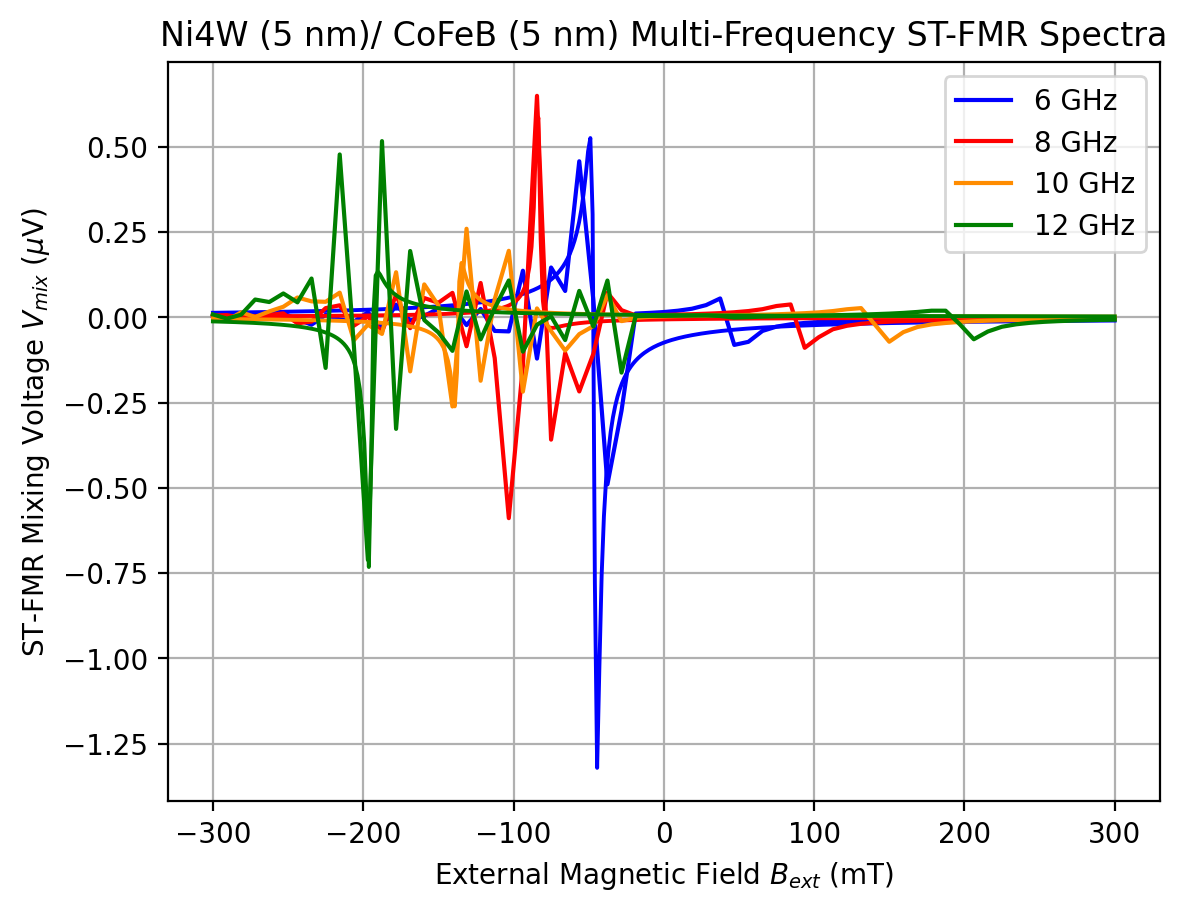

Extracted effective damping alpha_eff: -0.0000


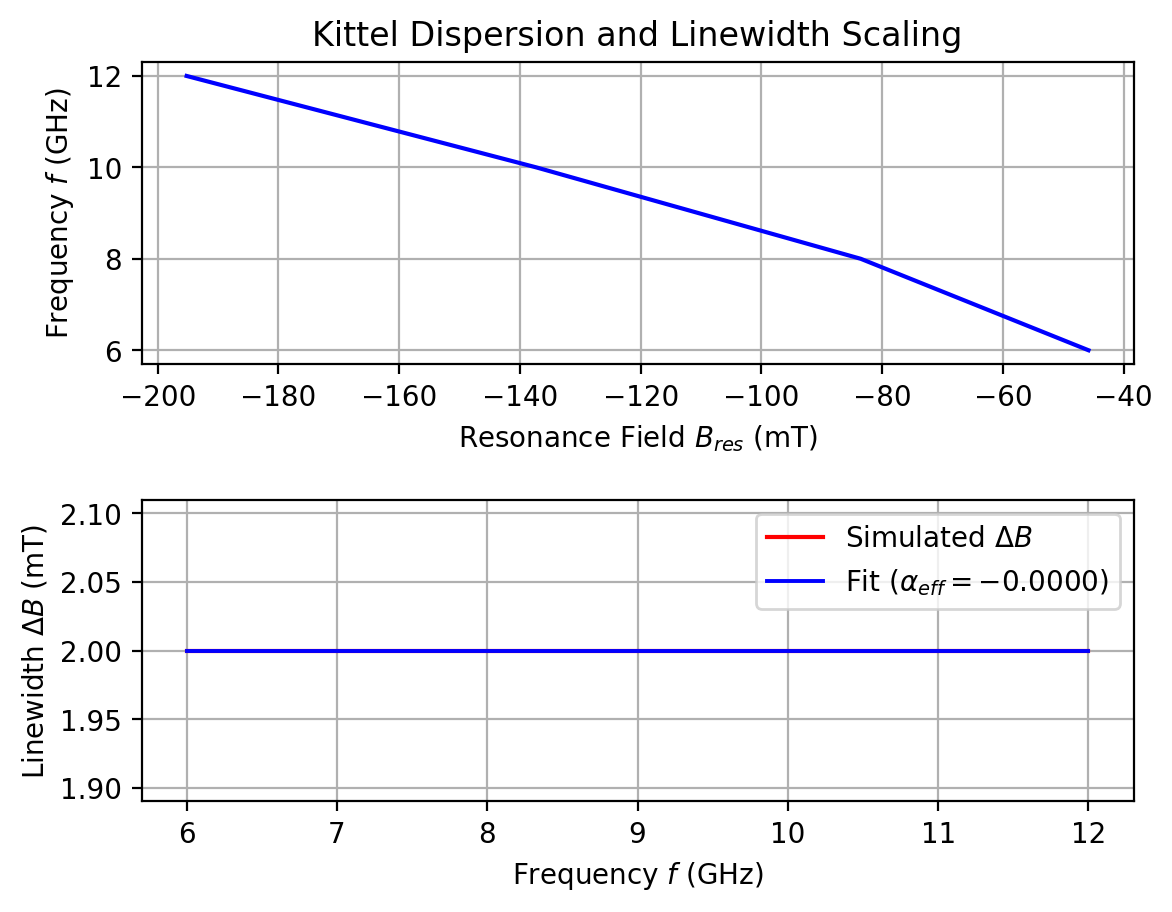

In [4]:
"""This script simulates multi-frequency ST-FMR in Ni4W(5 nm)/CoFeB(5 nm).

The simulation sweeps excitation frequency and magnetic field on a GPU,
extracting DC mixing spectra, Lorentzian fits, and resonance parameters.
"""

import math
import matplotlib.pyplot as plt
from mumaxplus import Ferromagnet
from mumaxplus import Grid
from mumaxplus import World
import numpy as np

plt.rcParams['figure.dpi'] = 200

mu0 = 4.0 * np.pi * 1e-7
hbar = 1.054571817e-34
q_e = 1.602176634e-19
gamma_ll = 1.7595e11

msat = 1.0e6
aex = 15.0e-12
ku1 = 1.28e5
alpha = 0.02
t_fm = 5.0e-9
t_hm = 5.0e-9
rho_hm = 1.50e-6
rho_fm = 2.27e-6
width_strip = 10.0e-6
delta_r = 0.2

theta_dl_x, theta_dl_y, theta_dl_z = 0.091, 0.727, -0.022
theta_fl_y, theta_fl_z = 0.577, 0.025

j_rf = 2.0e9
phi = np.deg2rad(45.0)
cos_p, sin_p = float(np.cos(phi)), float(np.sin(phi))

b_sot = (hbar * j_rf) / (2.0 * q_e * msat * t_fm)
b_oe = -0.5 * mu0 * j_rf * t_hm
b_rf = (
    theta_dl_z * b_sot * sin_p,
    theta_fl_y * b_sot + b_oe - theta_dl_z * b_sot * cos_p,
    (theta_dl_y * cos_p - theta_dl_x * sin_p + theta_fl_z) * b_sot,
)

i_rf = j_rf * width_strip * t_hm * (1.0 + (rho_hm * t_fm) / (rho_fm * t_hm))

world = World(cellsize=(4.0e-9, 4.0e-9, 5.0e-9))
magnet = Ferromagnet(world, Grid((16, 16, 1)))
magnet.msat = msat
magnet.aex = aex
magnet.ku1 = ku1
magnet.anisU = (0.0, 0.0, 1.0)
magnet.alpha = alpha

omega = 0.0
mask = np.ones((1, 16, 16))
magnet.bias_magnetic_field.add_time_term(
    lambda t: tuple(v * math.cos(omega * t) for v in b_rf), mask
)

f_list = [6.0e9, 8.0e9, 10.0e9, 12.0e9]
colors = ['blue', 'red', 'darkorange', 'green']
b_sweep = np.linspace(-0.3, 0.3, 65)
b_fit = np.linspace(b_sweep[0], b_sweep[-1], 400)
t_ringup = 2.0e-9
n_samples = 128
q_dict = {'mx': lambda: magnet.magnetization.average()[0]}

b_res_list = []
db_list = []
fig1, ax1 = plt.subplots()

for f_rf, color in zip(f_list, colors):
    omega = 2.0 * np.pi * f_rf
    dt = 8.0 / (f_rf * n_samples)
    t_sample = t_ringup + dt * np.arange(1, n_samples + 1)
    v_mix_list = []

    for b_ext in b_sweep:
        world.timesolver.time = 0.0
        world.timesolver.timestep = 1e-12
        world.bias_magnetic_field = (b_ext * cos_p, b_ext * sin_p, 0.0)
        magnet.magnetization = (cos_p, sin_p, 0.0)
        world.timesolver.run(t_ringup)
        output = world.timesolver.solve(t_sample, q_dict)
        t_ss = np.asarray(output['time'])
        mx_ss = np.asarray(output['mx'])
        v_mix_t = i_rf * np.cos(omega * t_ss) * delta_r * (mx_ss ** 2)
        v_mix_list.append(float(np.mean(v_mix_t)))

    v_mix = np.asarray(v_mix_list)
    b_peak = b_sweep[np.argmax(np.abs(v_mix))]
    best_err = np.inf
    best_params = (b_peak, 0.008, 0.0, 0.0)

    for b_c in np.linspace(b_peak - 0.020, b_peak + 0.020, 49):
        for db_c in np.linspace(0.002, 0.025, 37):
            denom = (b_sweep - b_c) ** 2 + db_c ** 2
            sym = (db_c ** 2) / denom
            asym = db_c * (b_sweep - b_c) / denom
            a_mat = np.column_stack((sym, asym))
            coeffs, _, _, _ = np.linalg.lstsq(a_mat, v_mix, rcond=None)
            err = float(np.sum((v_mix - a_mat @ coeffs) ** 2))
            if err < best_err:
                best_err = err
                best_params = (b_c, db_c, float(coeffs[0]), float(coeffs[1]))

    b_res, delta_b, v_s, v_a = best_params
    b_res_list.append(b_res)
    db_list.append(delta_b)
    d_fit = (b_fit - b_res) ** 2 + delta_b ** 2
    v_fit = (v_s * (delta_b ** 2) + v_a * delta_b * (b_fit - b_res)) / d_fit

    f_ghz = f_rf / 1e9
    print(f'{f_ghz:.0f} GHz: B_res = {b_res * 1e3:.2f} mT, '
          f'dB = {delta_b * 1e3:.2f} mT, V_S/V_A = {v_s / v_a:.2f}')
    ax1.plot(b_sweep * 1e3, v_mix * 1e6, '-', color=color, markersize=4,
             markerfacecolor='none', label=f'{f_ghz:.0f} GHz')
    ax1.plot(b_fit * 1e3, v_fit * 1e6, color=color, linewidth=1.4)

ax1.set_xlabel(r'External Magnetic Field $B_{ext}$ (mT)')
ax1.set_ylabel(r'ST-FMR Mixing Voltage $V_{mix}$ ($\mu$V)')
ax1.set_title('Ni4W (5 nm)/ CoFeB (5 nm) Multi-Frequency ST-FMR Spectra')
ax1.grid(True)
ax1.legend()
plt.show()

f_arr = np.asarray(f_list)
b_res_arr = np.asarray(b_res_list)
db_arr = np.asarray(db_list)
slope, db0 = np.polyfit(f_arr, db_arr, 1)
alpha_eff = slope * gamma_ll / (2.0 * np.pi)
print(f'Extracted effective damping alpha_eff: {alpha_eff:.4f}')

fig2, (ax2, ax3) = plt.subplots(2, 1)
ax2.plot(b_res_arr * 1e3, f_arr / 1e9, '-', color='blue', markersize=5)
ax2.set_xlabel(r'Resonance Field $B_{res}$ (mT)')
ax2.set_ylabel('Frequency $f$ (GHz)')
ax2.set_title('Kittel Dispersion and Linewidth Scaling')
ax2.grid(True)

ax3.plot(f_arr / 1e9, db_arr * 1e3, '-', color='red', markersize=5,
         markerfacecolor='none', label=r'Simulated $\Delta B$')
ax3.plot(f_arr / 1e9, (slope * f_arr + db0) * 1e3, color='blue',
         linewidth=1.4, label=f'Fit ($\\alpha_{{eff}} = {alpha_eff:.4f}$)')
ax3.set_xlabel('Frequency $f$ (GHz)')
ax3.set_ylabel(r'Linewidth $\Delta B$ (mT)')
ax3.grid(True)
ax3.legend()
plt.subplots_adjust(hspace=0.45)
plt.show()